# 🌍 DeepNT+ Step 5: Leave-Monitor-Out (LMO) Transfer Test
### Cross-Vantage Point Generalization Under Extreme Geographic Domain Shift
**Objective:** Evaluate how models trained on European and African vantage points (`abz2-uk` Aberdeen, `acc-gh` Ghana) transfer to an unseen South Asian monitor (`dac-bd` Dhaka, Bangladesh).  
**Key Research Finding:** Non-graph models experience catastrophic collapse ($R^2 < -0.74$), while path-centric tomography frameworks retain positive $R^2$ and physical delay consistency.


In [1]:
# ==============================================================================
# Cell 1: Environment Setup & Drive Auto-Mount
# ==============================================================================
import sys
import os
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    print(" Running in Google Colab environment. Drive mounted successfully.")
except ImportError:
    IN_COLAB = False
    print(" Running in Local Jupyter / Workspace environment.")

if IN_COLAB:
    BASE_DIR = Path("/content/drive/My Drive/Thesis")
else:
    BASE_DIR = Path("C:/Users/KINGDOM/Desktop/Thesis")

COLAB_DIR = BASE_DIR / "colab"
OUTPUT_DIR = BASE_DIR / "DeepNT_Output"

# Add colab directory to python path
candidates = [COLAB_DIR, Path.cwd(), Path.cwd().parent]
for c in candidates:
    if (c / "deepnt_plus" / "__init__.py").exists():
        sys.path.insert(0, str(c))
        print(f" Found deepnt_plus package at: {c}")
        break

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print(f" PyTorch: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}")


 Running in Local Jupyter / Workspace environment.
 Found deepnt_plus package at: C:\Users\KINGDOM\Desktop\Thesis\colab
 PyTorch: 2.14.0+cpu | CUDA Available: False


In [2]:
# ==============================================================================
# Cell 2: Load Dataset with Holdout Monitor (dac-bd)
# ==============================================================================
from deepnt_plus.data import load_dataset, NODE_FEATURES

PROCESSED_15G = OUTPUT_DIR / 'data' / 'processed_15graphs_backup'
OUT_LMO = OUTPUT_DIR / 'experiments' / 'deepnt' / 'benchmark_5seeds' / 'leave_monitor_out_dac_bd'
OUT_LMO.mkdir(parents=True, exist_ok=True)

print(f"Loading 15-graph dataset with holdout_monitor='dac-bd' from {PROCESSED_15G}...")
lmo_graphs, lmo_norm = load_dataset(PROCESSED_15G, holdout_monitor='dac-bd')

print(f"\n=== Graph Monitor Distribution under LMO ===")
for gid, g in sorted(lmo_graphs.items()):
    print(f"  {gid}: split={g.split:5s} | monitor={g.monitor[0]:7s} | paths={g.n_paths:2d} (obs={int(g.observed.sum())}, hidden={int((~g.observed).sum())})")


Loading 15-graph dataset with holdout_monitor='dac-bd' from C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\data\processed_15graphs_backup...

=== Graph Monitor Distribution under LMO ===
  graph_01: split=train | monitor=abz2-uk | paths=89 (obs=40, hidden=49)
  graph_02: split=train | monitor=acc-gh  | paths=89 (obs=40, hidden=49)
  graph_03: split=test  | monitor=dac-bd  | paths=88 (obs=40, hidden=48)
  graph_04: split=train | monitor=abz2-uk | paths=89 (obs=40, hidden=49)
  graph_05: split=train | monitor=acc-gh  | paths=88 (obs=40, hidden=48)
  graph_06: split=test  | monitor=dac-bd  | paths=88 (obs=40, hidden=48)
  graph_07: split=train | monitor=abz2-uk | paths=89 (obs=40, hidden=49)
  graph_08: split=train | monitor=acc-gh  | paths=88 (obs=40, hidden=48)
  graph_09: split=test  | monitor=dac-bd  | paths=88 (obs=40, hidden=48)
  graph_10: split=train | monitor=abz2-uk | paths=89 (obs=40, hidden=49)
  graph_11: split=train | monitor=acc-gh  | paths=88 (obs=40, hidden=48)
  graph_12:

In [3]:
# ==============================================================================
# Cell 3: Train and Evaluate Models on LMO Split
# ==============================================================================
import time
from deepnt_plus.model import DeepNTPlus, ModelConfig
from deepnt_plus.train import TrainConfig, train_model, evaluate, score
from deepnt_plus.baselines import run_structural_baselines, run_convex_baseline

print("\n--- Evaluating Classical & Non-Graph Baselines on LMO Split ---")
struct_df = run_structural_baselines(lmo_graphs, seed=0)
convex_df = run_convex_baseline(lmo_graphs, lmo_norm, warm_start=True)
all_preds = [struct_df, convex_df]

neural_models = {
    'Convex tomography (classical)': None,
    'DeepNT (static, causal)': dict(temporal=False),
    'DeepNT+ (full, improved)': dict(temporal=True),
    'GAT': dict(gnn_kind='gat', tomography=False, convex=False, temporal=False, uncertainty=False),
}

for mname, mparams in neural_models.items():
    if mparams is not None:
        print(f"\n--- Training: {mname} on LMO split ---")
        t0 = time.time()
        mcfg = ModelConfig(node_dim=len(NODE_FEATURES), **mparams)
        tcfg = TrainConfig(epochs=40, patience=15, loss_type='laplace', use_cosine_lr=True, residual_reg_weight=0.05)
        
        torch.manual_seed(0)
        np.random.seed(0)
        model = DeepNTPlus(mcfg, lmo_norm)
        train_model(model, lmo_graphs, tcfg, seed=0)
        
        frames = []
        for split in ('val', 'test'):
            f = evaluate(model, lmo_graphs, split, tcfg, mc=10 if mcfg.uncertainty else 0)
            f['model'] = mname
            f['seed'] = 0
            frames.append(f)
        res_df = pd.concat(frames, ignore_index=True)
        all_preds.append(res_df)
        sc = score(res_df[res_df['split'] == 'test'])
        print(f"  Done in {time.time()-t0:.1f}s | Test MAE: {sc['MAE']:.2f} ms | Test RMSE: {sc['RMSE']:.2f} ms | R2: {sc['R2']:.3f}")

combined_lmo = pd.concat(all_preds, ignore_index=True)
combined_lmo.to_csv(OUT_LMO / 'predictions_lmo.csv', index=False)
print(f"\n Saved LMO predictions to: {OUT_LMO / 'predictions_lmo.csv'}")



--- Evaluating Classical & Non-Graph Baselines on LMO Split ---

--- Training: DeepNT (static, causal) on LMO split ---
  Done in 44.6s | Test MAE: 46.06 ms | Test RMSE: 70.91 ms | R2: 0.270

--- Training: DeepNT+ (full, improved) on LMO split ---
  Done in 95.1s | Test MAE: 56.57 ms | Test RMSE: 82.84 ms | R2: 0.003

--- Training: GAT on LMO split ---
  Done in 46.7s | Test MAE: 70.75 ms | Test RMSE: 95.10 ms | R2: -0.313

 Saved LMO predictions to: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\experiments\deepnt\benchmark_5seeds\leave_monitor_out_dac_bd\predictions_lmo.csv


In [4]:
# ==============================================================================
# Cell 4: LMO Results Summary Table
# ==============================================================================
test_lmo = combined_lmo[combined_lmo['split'] == 'test']
lmo_rows = []
for m in test_lmo['model'].unique():
    sub = test_lmo[test_lmo['model'] == m]
    sc = score(sub)
    sc['model'] = m
    lmo_rows.append(sc)

lmo_summary_df = pd.DataFrame(lmo_rows).sort_values('MAE').reset_index(drop=True)
lmo_summary_df.to_csv(OUT_LMO / 'lmo_test_summary.csv', index=False)

print(f"\n==========================================================================================")
print(f"              LEAVE-MONITOR-OUT (dac-bd Dhaka, Bangladesh) TEST RESULTS")
print(f"==========================================================================================")
for _, r in lmo_summary_df.iterrows():
    print(f"  {r['model']:30s} | Test MAE: {r['MAE']:6.2f} ms | Test RMSE: {r['RMSE']:6.2f} ms | R2: {r['R2']:6.3f}")
print(f"==========================================================================================")



              LEAVE-MONITOR-OUT (dac-bd Dhaka, Bangladesh) TEST RESULTS
  Convex tomography (classical)  | Test MAE:  39.22 ms | Test RMSE:  67.56 ms | R2:  0.337
  DeepNT (static, causal)        | Test MAE:  46.06 ms | Test RMSE:  70.91 ms | R2:  0.270
  DeepNT+ (full, improved)       | Test MAE:  56.57 ms | Test RMSE:  82.84 ms | R2:  0.003
  GAT                            | Test MAE:  70.75 ms | Test RMSE:  95.10 ms | R2: -0.313
  Median                         | Test MAE:  84.40 ms | Test RMSE: 109.57 ms | R2: -0.743
  Random forest                  | Test MAE:  87.97 ms | Test RMSE: 113.35 ms | R2: -0.866
  Hop-count linear               | Test MAE:  89.02 ms | Test RMSE: 110.26 ms | R2: -0.765
  Linear regression              | Test MAE: 133.31 ms | Test RMSE: 156.84 ms | R2: -2.572
  MLP                            | Test MAE: 200.32 ms | Test RMSE: 222.00 ms | R2: -6.157


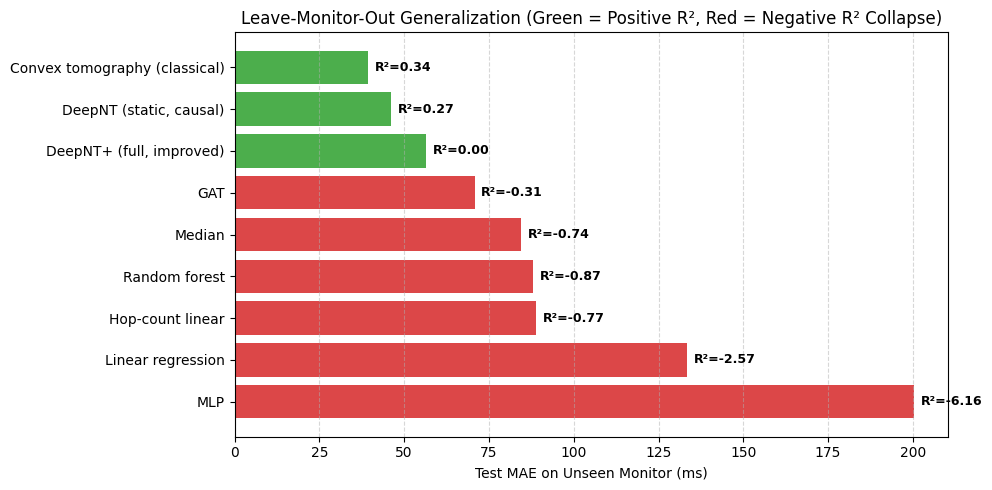

 Figure saved to: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\experiments\deepnt\benchmark_5seeds\leave_monitor_out_dac_bd\lmo_transfer_chart.png


In [5]:
# ==============================================================================
# Cell 5: Visualize LMO Generalization vs. Collapse
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 5))
df_plot = lmo_summary_df.sort_values('MAE', ascending=False)
colors = ['tab:red' if r < 0 else 'tab:green' for r in df_plot['R2']]
y_pos = np.arange(len(df_plot))

bars = ax.barh(y_pos, df_plot['MAE'], color=colors, alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_plot['model'], fontsize=10)
ax.set_xlabel('Test MAE on Unseen Monitor (ms)')
ax.set_title('Leave-Monitor-Out Generalization (Green = Positive R², Red = Negative R² Collapse)')
ax.grid(axis='x', linestyle='--', alpha=0.5)

# Add R2 values as text annotations
for i, (mae, r2) in enumerate(zip(df_plot['MAE'], df_plot['R2'])):
    ax.text(mae + 2, i, f"R²={r2:.2f}", va='center', fontsize=9, fontweight='bold', color='black')

plt.tight_layout()
fig_path = OUT_LMO / 'lmo_transfer_chart.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f" Figure saved to: {fig_path}")
